In [1]:
import seaborn as sns

In [2]:
df = sns.load_dataset('iris')

In [3]:
df.drop(columns=['species'],inplace=True)

In [4]:
df.shape

(150, 4)

In [5]:
df.head(2)

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2


In [12]:
# Keep species separately for visualization
df = sns.load_dataset('iris')
y = df['species']
X = df.drop(columns=['species'])

In [14]:
from sklearn.preprocessing import StandardScaler
#Scale Features before dimensionality Reduction
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Orignal shape:",X.shape)
print("Scaled shape:",X_scaled.shape)

Orignal shape: (150, 4)
Scaled shape: (150, 4)


In [15]:
#==============================================
#1.PCA
#==============================================
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)
print("Explained variance ratio:",pca.explained_variance_ratio_)
print("Total variance explained:",pca.explained_variance_ratio_.sum())

PCA shape: (150, 2)
Explained variance ratio: [0.72962445 0.22850762]
Total variance explained: 0.9581320720000163


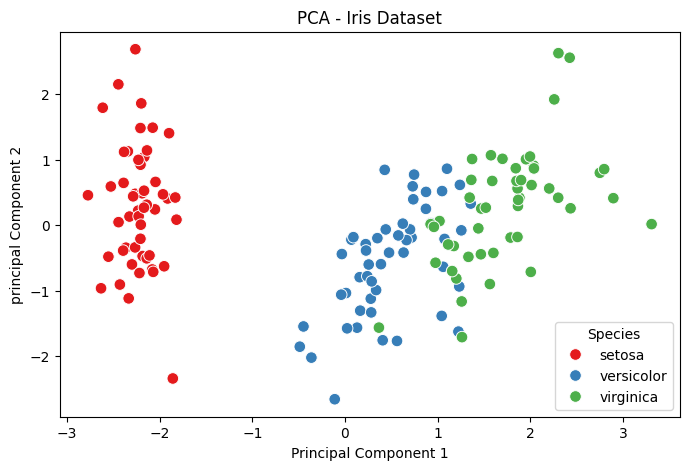

In [16]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=y,
    palette='Set1',
    s=70
    )
plt.title("PCA - Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("principal Component 2")
plt.legend(title="Species")
plt.show()

In [17]:
#=================================
#2.t-SNE
#=================================
from sklearn.manifold import TSNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
    learning_rate='auto'
    )
X_tsne = tsne.fit_transform(X_scaled)
print("t-SNE shape:",X_tsne.shape)

t-SNE shape: (150, 2)


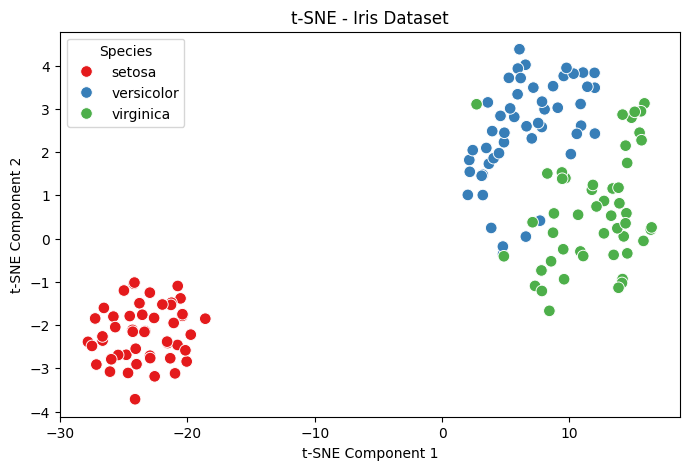

In [18]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x=X_tsne[:,0],
    y=X_tsne[:,1],
    hue=y,
    palette='Set1',
    s=70
    )
plt.title("t-SNE - Iris Dataset")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="Species")
plt.show()

In [ ]:
#=================================
#3.UMAP
#=================================
#If UMAP is not installed,run:
#!pip install umap-learn

In [ ]:
# !pip install umap-learn
pip install umap-learn


   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ---------------------------------------- 2.8/2.8 MB 25.5 MB/s  0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
    --------------------------------------- 0.8/41.9 MB 14.5 MB/s eta 0:00:03
   -- ------------------------------------- 2.9/41.9 MB 12.4 MB/s eta 0:00:04
   ---- ----------------------------------- 4.2/41.9 MB 8.4 MB/s eta 0:00:05
   ---- ----------------------------------- 4.7/41.9 MB 7.1 MB/s eta 0:00:06
   ----- ---------------------------------- 5.2/41.9 MB 5.7 MB/s eta 0:00:07
   ----- ---------------------------------- 5.5/41.9 MB 5.4 MB/s eta 0:00:07
   ------ --------------------------------- 6.3/41.9 MB 4.6 MB/s eta 0:00:08
   ------- -------------------------------- 7.3/41.9 MB 4.6 MB/s eta 0:00:08
   -------- ------------------------------- 8.4/41.9 MB 4.7 MB/s eta 0:00:08
   --------- ---------

In [7]:
from umap import UMAP

In [19]:
reducer = UMAP(n_components=2, random_state=42)

In [21]:
X=reducer.fit_transform(X_scaled)

c:\Users\dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [23]:
print("UMAP shape:"X.shape)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1015428037.py, line 1)

In [11]:
X.shape

(150, 2)

In [24]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_umap[:, 0],
    y=X_umap[:, 1],
    hue=y,
    palette='Set1',
    s=70
)
plt.title("UMAP - Iris Dataset")
plt.xlabel("UMAP Component 1")
plt.ylabel("UMAP Component 2")
plt.legend(title="Species")
plt.show()


NameError: name 'X_umap' is not defined

<Figure size 800x500 with 0 Axes>

NameError: name 'X_umap' is not defined

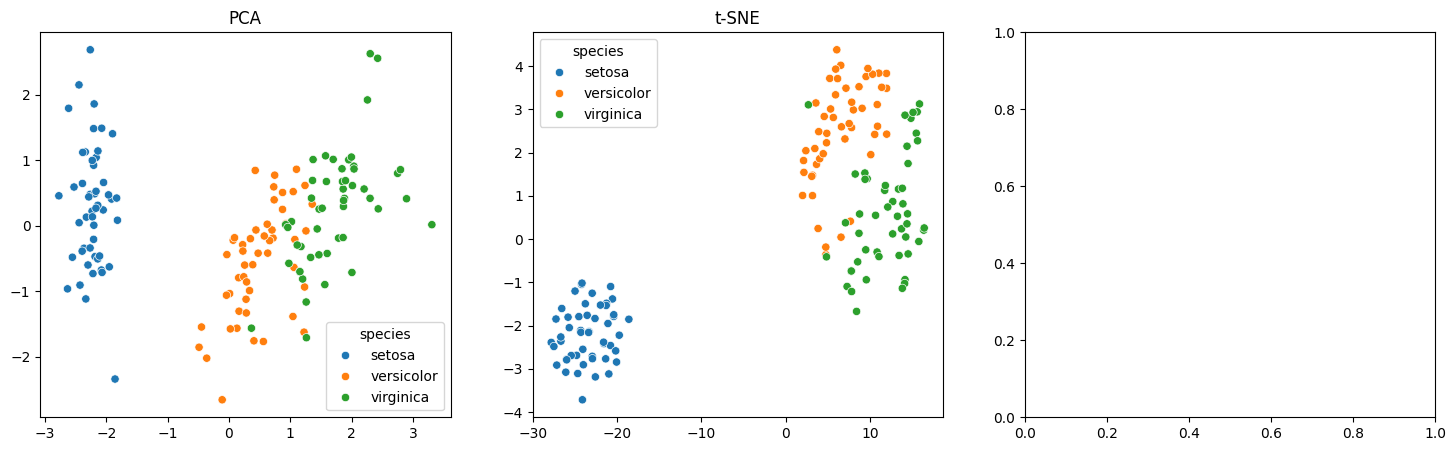

In [ ]:
# =========================
# Compare all three methods
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='Set1', s=60, ax=axes[0], legend=False)
axes[0].set_title("PCA")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette='Set1', s=60, ax=axes[1], legend=False)
axes[1].set_title("t-SNE")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=y, palette='Set1', s=60, ax=axes[2])
axes[2].set_title("UMAP")
axes[2].set_xlabel("UMAP 1")
axes[2].set_ylabel("UMAP 2")

plt.tight_layout()
plt.show()
